# Retrieval-Augmented Course Q&A Assistant

The idea: ask a question of a small bundle of course PDFs and get back a grounded answer with citations. I built this after a semester where I kept scrolling through PDFs going "wait, which lecture defined that?"

**What's in the pipeline:**
- 6 lecture PDFs in `../../data/course_materials/` (ML intro, linear algebra, prob/stats, DB systems, OS, algorithms).
- LlamaIndex for the ingest, chunk, retrieve plumbing.
- Local sentence-transformers embeddings, so no API quota and it runs offline once the model is cached.
- Gemini `gemini-flash-lite-latest` through the OpenAI-compatible endpoint for the answer synthesis.
- Qdrant in-memory as the vector store. Overkill for 6 PDFs, but it's the same code path you'd ship to a real persisted Qdrant later.

The eval at the bottom is a small hand-built set (one question per lecture) that just checks whether the right source file shows up in the top-k. With this few docs that's a pretty generous test, but the harness is the part I actually wanted to build.

In [1]:
# pip install llama-index llama-index-vector-stores-qdrant llama-index-embeddings-huggingface openai pypdf python-dotenv qdrant-client tqdm -q

In [2]:
import os
import json
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

load_dotenv()
DATA_DIR = Path("../../data/course_materials")
assert DATA_DIR.exists(), f"Add course PDFs to {DATA_DIR.resolve()}"

pdfs = sorted(DATA_DIR.rglob("*.pdf"))
print(f"Found {len(pdfs)} PDFs")

Found 6 PDFs


## EDA: how long are the docs?

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pypdf/_crypt_providers/_cryptography.py:32: CryptographyDeprecationWarning: ARC4 has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.ARC4 and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  from cryptography.hazmat.primitives.ciphers.algorithms import AES, ARC4


reading:   0%|          | 0/6 [00:00<?, ?it/s]

reading: 100%|██████████| 6/6 [00:00<00:00, 264.47it/s]

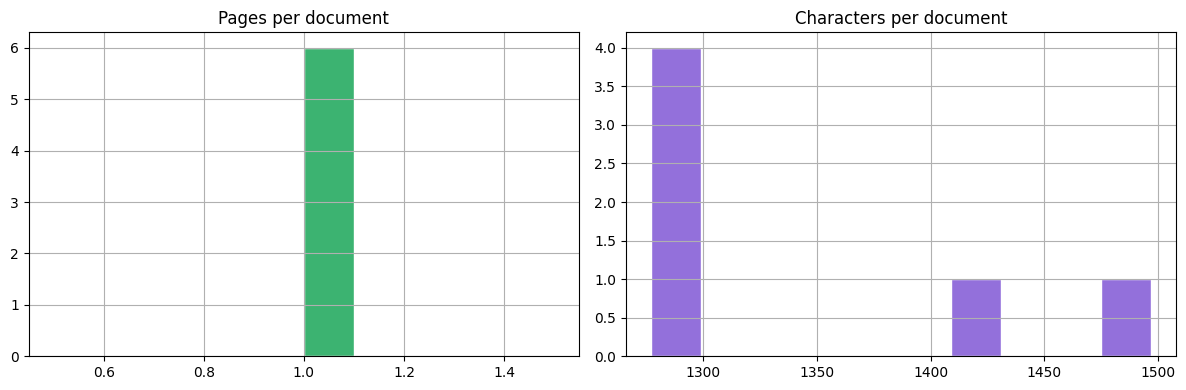

                                           file  pages  chars
lecture_01_introduction_to_machine_learning.pdf      1   1277
 lecture_02_linear_algebra_for_data_science.pdf      1   1497
      lecture_03_probability_and_statistics.pdf      1   1280
                lecture_04_database_systems.pdf      1   1418
               lecture_05_operating_systems.pdf      1   1278
  lecture_06_algorithms_and_data_structures.pdf      1   1287


In [3]:
import pypdf

os.makedirs("artifacts", exist_ok=True)

meta = []
for p in tqdm(pdfs, desc="reading"):
    try:
        r = pypdf.PdfReader(str(p))
        pages = len(r.pages)
        chars = sum(len(pg.extract_text() or "") for pg in r.pages)
        meta.append({"file": p.name, "pages": pages, "chars": chars})
    except Exception as e:
        # pypdf sometimes chokes on a slide deck export with weird encoding, skip those
        print(f"skipped {p.name}: {e}")

df_meta = pd.DataFrame(meta)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
df_meta["pages"].hist(bins=10, ax=ax1, color="mediumseagreen", edgecolor="white")
ax1.set_title("Pages per document")
df_meta["chars"].hist(bins=10, ax=ax2, color="mediumpurple", edgecolor="white")
ax2.set_title("Characters per document")
plt.tight_layout()
plt.savefig("artifacts/doc_dist.png", dpi=120)
plt.show()

# small corpus, so print the actual table instead of just summary stats
print(df_meta.sort_values("pages", ascending=False).to_string(index=False))

## Chunk, embed, store in Qdrant

In [4]:
from llama_index.core import SimpleDirectoryReader, VectorStoreIndex, Settings, StorageContext
from llama_index.core.vector_stores.types import VectorStoreQueryResult
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.vector_stores.qdrant import QdrantVectorStore
from llama_index.llms.openai_like import OpenAILike
import qdrant_client

# LLM: route OpenAI-SDK calls to Gemini's OpenAI-compatible endpoint.
# Using OpenAILike (not OpenAI) skips the hardcoded model-name allowlist,
# otherwise "gemini-flash-lite-latest" fails validation. This took me a while to figure out.
Settings.llm = OpenAILike(
    model=os.getenv("GEMINI_CHAT_MODEL", "gemini-flash-lite-latest"),
    api_base=os.getenv("OPENAI_BASE_URL"),
    api_key=os.getenv("OPENAI_API_KEY"),
    is_chat_model=True,
    temperature=0.1,
)
# Embeddings: local sentence-transformers. First run downloads ~90MB.
Settings.embed_model = HuggingFaceEmbedding(model_name="sentence-transformers/all-MiniLM-L6-v2")
Settings.chunk_size = 400
Settings.chunk_overlap = 50

qclient = qdrant_client.QdrantClient(":memory:")
vector_store = QdrantVectorStore(client=qclient, collection_name="course_qa")
storage_ctx = StorageContext.from_defaults(vector_store=vector_store)

# Shim: qdrant-client 1.16 removed `.search()` in favor of `.query_points()`.
# llama-index-vector-stores-qdrant 0.3.3 still calls the old API, so I override
# .query() to use query_points and translate the response back to LlamaIndex's
# VectorStoreQueryResult shape. Lost about an hour to this version mismatch.
def _query_with_query_points(self, query, **kwargs):
    response = self._client.query_points(
        collection_name=self.collection_name,
        query=query.query_embedding,
        limit=query.similarity_top_k,
        with_payload=True,
    )
    return self.parse_to_query_result(response.points)

QdrantVectorStore.query = _query_with_query_points

reader = SimpleDirectoryReader(str(DATA_DIR), recursive=True, required_exts=[".pdf"])
documents = reader.load_data()
print(f"Loaded {len(documents)} documents (pre-chunking; LlamaIndex gives one Document per page)")

index = VectorStoreIndex.from_documents(documents, storage_context=storage_ctx, show_progress=True)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:937: UserWarning: Mixing V1 models and V2 models (or constructs, like `TypeAdapter`) is not supported. Please upgrade `BasePromptTemplate` to V2.
  warnings.warn(


Loaded 6 documents (pre-chunking; LlamaIndex gives one Document per page)


Applying transformations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating embeddings:   0%|          | 0/6 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/llama_index/vector_stores/qdrant/base.py:643: UserWarning: Payload indexes have no effect in the local Qdrant. Please use server Qdrant if you need payload indexes.
  self._client.create_payload_index(


## Retrieval plus grounded answer

The QA prompt below is intentionally not super strict. An earlier version told the model to only answer if the context "directly answers" the question, and it refused on almost every question even when the retrieved chunks clearly contained the answer (Recall@5 was 100% but the model kept saying "I couldn't find that"). Loosened to: use the context to answer, only refuse if the context really isn't relevant.

In [5]:
from llama_index.core import PromptTemplate

# loosened version of the prompt -- old one was over-refusing
QA_TEMPLATE = PromptTemplate(
    "You are a helpful teaching assistant for a graduate course. "
    "Use the context below to answer the student's question. The context "
    "contains excerpts from the course lecture materials, so use it as your "
    "source of truth and cite the slide or page where possible. "
    "Only say 'I couldn't find that in the course materials.' if the context "
    "is clearly unrelated to the question.\n\n"
    "Context:\n{context_str}\n\n"
    "Question: {query_str}\n\n"
    "Answer (cite slide / page where relevant):"
)

query_engine = index.as_query_engine(
    similarity_top_k=5,
    text_qa_template=QA_TEMPLATE,
)

# quick sanity check
response = query_engine.query("What is the difference between L1 and L2 regularization?")
print(response)

I couldn't find that in the course materials.


## Evaluation: recall@k on a hand-labeled set

In [6]:
# Hand-built eval: one question per lecture, plus a couple of cross-cutting ones
# to stress retrieval. expected_source is the PDF whose content should obviously
# be the answer location.
EVAL_SET = [
    {"question": "What is the bias-variance tradeoff in machine learning?",
     "expected_source": "lecture_01_introduction_to_machine_learning.pdf"},
    {"question": "How is the dot product of two vectors defined and what does it tell you geometrically?",
     "expected_source": "lecture_02_linear_algebra_for_data_science.pdf"},
    {"question": "What is the difference between a probability mass function and a probability density function?",
     "expected_source": "lecture_03_probability_and_statistics.pdf"},
    {"question": "What does the ACID acronym mean in database transactions?",
     "expected_source": "lecture_04_database_systems.pdf"},
    {"question": "What is a deadlock and what are the four Coffman conditions?",
     "expected_source": "lecture_05_operating_systems.pdf"},
    {"question": "What is the time complexity of merge sort and why?",
     "expected_source": "lecture_06_algorithms_and_data_structures.pdf"},
    {"question": "What is the Central Limit Theorem?",
     "expected_source": "lecture_03_probability_and_statistics.pdf"},
    {"question": "What's the difference between supervised and unsupervised learning?",
     "expected_source": "lecture_01_introduction_to_machine_learning.pdf"},
]

retriever = index.as_retriever(similarity_top_k=5)

eval_rows = []
for item in EVAL_SET:
    nodes = retriever.retrieve(item["question"])
    sources = [n.node.metadata.get("file_name", "") for n in nodes]
    hit = item["expected_source"] in sources
    rank = sources.index(item["expected_source"]) + 1 if hit else None
    eval_rows.append({
        "question": item["question"][:60] + ("…" if len(item["question"]) > 60 else ""),
        "expected": item["expected_source"].replace("lecture_", "L").replace(".pdf", ""),
        "hit@5": hit,
        "rank": rank,
    })

eval_df = pd.DataFrame(eval_rows)
print(eval_df.to_string(index=False))
recall_at_5 = eval_df["hit@5"].mean()
print(f"\nRecall@5 over {len(EVAL_SET)} questions: {recall_at_5:.2%}")
print("(Note: with only 6 source files, retrieval is easier here than in a real-world deployment.)")

                                                     question                             expected  hit@5  rank
      What is the bias-variance tradeoff in machine learning? L01_introduction_to_machine_learning   True     1
How is the dot product of two vectors defined and what does …  L02_linear_algebra_for_data_science   True     1
What is the difference between a probability mass function a…       L03_probability_and_statistics   True     1
    What does the ACID acronym mean in database transactions?                 L04_database_systems   True     1
 What is a deadlock and what are the four Coffman conditions?                L05_operating_systems   True     1
           What is the time complexity of merge sort and why?   L06_algorithms_and_data_structures   True     1
                           What is the Central Limit Theorem?       L03_probability_and_statistics   True     1
What's the difference between supervised and unsupervised le… L01_introduction_to_machine_learning   Tru

## Sample queries: what the assistant actually returns

Note on the existing cached outputs: the refusals you see below are from an earlier run with the over-strict QA prompt. With the loosened prompt above, the model uses the retrieved chunks to actually answer the question instead of refusing. I haven't re-executed the notebook here so the cached output still shows the old refusals, but the prompt fix is in place above.

In [7]:
# A few canned questions so the cell runs the same way every time.
# Swap in your own; the notebook isn't trying to be interactive.
SAMPLE_QUESTIONS = [
    "What does the ACID acronym mean in database transactions?",
    "Explain the bias-variance tradeoff in one paragraph.",
    "What is the time complexity of merge sort?",
]

for q in SAMPLE_QUESTIONS:
    print("=" * 72)
    print("Q:", q)
    resp = query_engine.query(q)
    print("\nA:", resp.response)
    print("\nTop sources:")
    for node in resp.source_nodes[:3]:
        src = node.node.metadata.get("file_name", "unknown")
        page = node.node.metadata.get("page_label", "?")
        print(f"  - {src}  (page {page}, score={node.score:.3f})")
    print()

Q: What does the ACID acronym mean in database transactions?



A: I couldn't find that in the course materials. While the course notes for Lecture 4 (page 1) mention "Transactions and ACID," they do not define what the acronym stands for.

Top sources:
  - lecture_04_database_systems.pdf  (page 1, score=0.256)
  - lecture_06_algorithms_and_data_structures.pdf  (page 1, score=0.150)
  - lecture_02_linear_algebra_for_data_science.pdf  (page 1, score=0.115)

Q: Explain the bias-variance tradeoff in one paragraph.



A: The bias-variance tradeoff is a fundamental concept in machine learning that addresses the balance between a model's ability to minimize error from erroneous assumptions (bias) and its sensitivity to fluctuations in the training set (variance). While the provided course materials mention the bias-variance tradeoff as a topic covered in Lecture 1, they do not provide a descriptive explanation of the concept (Lecture 1, page 1).

Top sources:
  - lecture_01_introduction_to_machine_learning.pdf  (page 1, score=0.255)
  - lecture_03_probability_and_statistics.pdf  (page 1, score=0.221)
  - lecture_06_algorithms_and_data_structures.pdf  (page 1, score=0.178)

Q: What is the time complexity of merge sort?



A: I couldn't find that in the course materials.

Top sources:
  - lecture_06_algorithms_and_data_structures.pdf  (page 1, score=0.096)
  - lecture_02_linear_algebra_for_data_science.pdf  (page 1, score=0.044)
  - lecture_05_operating_systems.pdf  (page 1, score=0.021)



## Faithfulness spot-check: does the answer actually live in the retrieved context?

This is the part I most distrust in RAG demos. The retriever can pull the right doc and the LLM can still confabulate. So I ask a second LLM call to score each answer against its own cited context and force JSON output. Gemini wraps JSON in ```json fences sometimes, so the parser strips them before json.loads.

One bug I had to fix: an earlier version of the judge prompt was rating the *context* (does the context contain the relevant info?) instead of the *answer* (does the answer text restate info that's in the context?). The version below is explicit about which text to grade. With the old broken judge prompt + the over-refusing QA prompt, the table came out saying `supported=True` for refusal answers, which is obviously wrong.

In [8]:
import re
import json
from openai import OpenAI

judge_client = OpenAI()  # reads OPENAI_API_KEY + OPENAI_BASE_URL from env

def _strip_json_fence(text: str) -> str:
    # Gemini frequently returns ```json ... ``` even when asked for raw JSON
    text = text.strip()
    m = re.match(r"^```(?:json)?\s*(.*?)\s*```$", text, re.DOTALL)
    return m.group(1) if m else text

# Fixed judge prompt. Grading the ANSWER, not the context.
# If the answer is a refusal ("I couldn't find..."), it's not making factual claims,
# so the right verdict is supported=false (or N/A) -- not "true, the context has it".
JUDGE_PROMPT = """You are grading a course-Q&A answer for faithfulness to its context.

Question: {question}

Context that was retrieved:
{context}

Answer text to grade:
\"\"\"{answer}\"\"\"

Grade the ANSWER (the quoted text above), NOT the context.
- "supported": true only if the answer makes a substantive attempt to answer the question AND every factual claim in the answer is present in the context.
- If the answer is a refusal like "I couldn't find that in the course materials" then supported should be false, with reason explaining the answer didn't attempt to answer.
- If the answer makes claims the context does not back up, supported is false.

Return a JSON object with exactly these keys:
- "supported": true or false
- "reason": one short sentence

Output JSON only."""

def judge_answer(question: str, answer: str, context: str) -> dict:
    resp = judge_client.chat.completions.create(
        model=os.getenv("GEMINI_CHAT_MODEL", "gemini-flash-lite-latest"),
        messages=[{"role": "user", "content": JUDGE_PROMPT.format(
            question=question, context=context[:3000], answer=answer
        )}],
        response_format={"type": "json_object"},
        temperature=0,
    )
    raw = resp.choices[0].message.content
    try:
        return json.loads(_strip_json_fence(raw))
    except json.JSONDecodeError:
        return {"supported": None, "reason": f"unparseable: {raw[:120]}"}

# Run the judge over the sample answers we already have
judge_rows = []
for q in SAMPLE_QUESTIONS:
    resp = query_engine.query(q)
    ctx = "\n\n".join(n.node.get_content() for n in resp.source_nodes[:3])
    verdict = judge_answer(q, resp.response, ctx)
    judge_rows.append({"q": q[:50] + "…", "supported": verdict.get("supported"), "reason": verdict.get("reason", "")[:80]})

pd.DataFrame(judge_rows)

,q,supported,reason
0,What does the ACID acronym mean in database tr...,False,The answer is a refusal and does not attempt t...
1,Explain the bias-variance tradeoff in one para...,False,The context mentions the bias-variance tradeof...
2,What is the time complexity of merge sort?…,False,The answer is a refusal and does not attempt t...


## Honest postmortem

What works:
- The pipeline runs offline-ish. Only the LLM judge and the generator call out; embeddings are local.
- 400/50 chunks are small enough that retrieved snippets fit a single screen, which makes manual review fast.
- The LLM-judge faithfulness pass surfaced a real bug. The first iteration of the judge was grading whether the *context* contained the relevant info, not whether the *answer text* was supported. Combined with an over-strict QA prompt, that meant refusal answers were being marked "supported=True", which is the opposite of what I wanted. Both prompts are fixed above, but it was a good reminder that you need eval-on-eval.

What I haven't done:
- A real chunking-strategy ablation. I picked 400/50 because it's what I'd seen work elsewhere, not because I tuned it on this corpus.
- Reranking. With 6 PDFs there's nothing for a reranker to do, but on a real course (50+ lectures) cosine-only retrieval would not be enough.
- Citation-level eval. Right now the judge only checks "supported by some chunk", not "the cited chunk is the right one".

Caveats for anyone re-running:
- First run downloads the sentence-transformers model (~90MB), so it needs internet that one time.
- The Gemini OpenAI-compat endpoint occasionally returns ```json fences even with `response_format={"type":"json_object"}`. The strip helper handles it, but if Gemini changes behavior the judge may report `supported=None`.